# 02 - Cox Proportional Hazards Model

**Goal:** Estimate how several variables affect the risk of re-arrest at the same time,
interpret hazard ratios, and check the proportional hazards (PH) assumption.

**Dataset:** rossi (432 people, 52 weeks, event = re-arrest).

**Covariates:**
| Column | Meaning |
|---|---|
| fin | Financial aid (1 = yes) |
| age | Age at release (years) |
| race | 1 = Black, 0 = other |
| wexp | Full-time work experience before prison (1 = yes) |
| mar | Married at release (1 = yes) |
| paro | Released on parole (1 = yes) |
| prio | Number of prior convictions |

In [1]:
!pip install -q matplotlib
!pip install -q lifelines

In [6]:
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter
from lifelines.datasets import load_rossi
from lifelines.statistics import proportional_hazard_test

df = load_rossi()
df.head()

,week,arrest,fin,age,race,wexp,mar,paro,prio
0,20,1,0,27,1,0,0,1,3
1,17,1,0,18,1,0,0,1,8
2,25,1,0,19,0,1,0,1,13
3,52,0,1,23,1,1,1,1,1
4,52,0,0,19,0,1,0,1,3


## 2. Fit the Cox model

Unlike KaplanMeierFitter, CoxPHFitter takes the **whole DataFrame**:
- duration_col="week" - which column is the time
- event_col="arrest" - which column is the event flag
- **Every other column** is automatically used as a covariate.

In [12]:
cph = CoxPHFitter()
cph.fit(df, duration_col="week", event_col="arrest")
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 432 total observations, 318 right-censored observations>
             duration col = 'week'
                event col = 'arrest'
      baseline estimation = breslow
   number of observations = 432
number of events observed = 114
   partial log-likelihood = -658.75
         time fit was run = 2026-11-17 15:06:14 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
fin       -0.38      0.68      0.19           -0.75           -0.00                0.47                1.00
age       -0.06      0.94      0.02           -0.10           -0.01                0.90                0.99
race       0.31      1.37      0.31           -0.29            0.92                0.75                2.50
wexp      -0.15      0.86      0.21           -0.57            0.27                0.57                1.30
mar       -0.43      0.65      0.38           -1.18            0.31                0.31                1.37
paro      -0.08      0.92      0.20           -0.47            0.30                0.63                1.35
prio       0.09      1.10      0.03            0.04            0.15                1.04                1.16

           cmp to     z      p  -log2(p)
covariate                               
fin          0.00 -1.98   0.05      4.40
age          0.00 -2.61   0.01      6.79
race         0.00  1.02   0.31      1.70
wexp         0.00 -0.71   0.48      1.06
mar          0.00 -1.14   0.26      1.97
paro         0.00 -0.43   0.66      0.59
prio         0.00  3.19 <0.005      9.48
---
Concordance = 0.64
Partial AIC = 1331.50
log-likelihood ratio test = 33.27 on 7 df
-log2(p) of ll-ratio test = 15.37

## 3. Interpret Summary table

| Column | Meaning |
|---|---|
| coef | β, the log hazard ratio. Negative = protective, positive = harmful |
| exp(coef) | **Hazard ratio (HR)** - the number to interpret |
| exp(coef) lower/upper 95% | 95% confidence interval for the HR. If it **includes 1**, the effect is not clearly different from "no effect" |
| p | p-value testing HR = 1 |

**HR Means:**
- HR = 0.68 → hazard is 32% **lower** (1 − 0.68 = 0.32)
- HR = 1.10 → hazard is 10% **higher**
- Always add "**holding the other variables constant**".

**Concordance**  is the C-index: how well the model ranks who is arrested sooner.
0.5 = random guessing, 1.0 = perfect.

## 4. Visualize the hazard ratios

cph.plot() draws each coefficient with its 95% confidence interval.
- The x-axis shows **log(HR)** (the coefficient), so the "no effect" line is at **0** (= HR of 1).
- Intervals that **cross 0** are not statistically clear.
- Intervals entirely left of 0 = protective; entirely right = harmful.

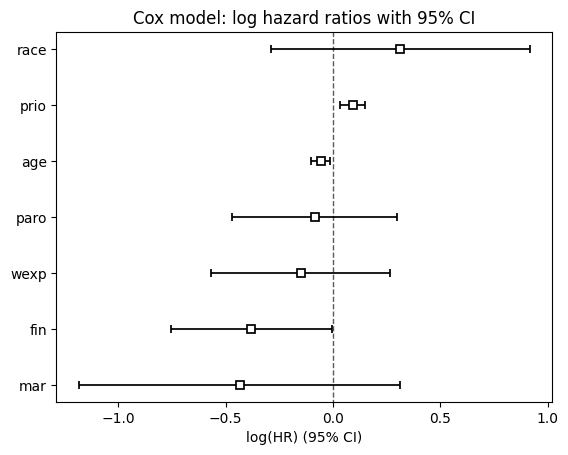

In [18]:
cph.plot()
plt.title("Cox model: log hazard ratios with 95% CI")
plt.show()

## 5. What does a covariate do to the survival curve?

`plot_partial_effects_on_outcome` shows predicted survival curves for different values of one variable,
holding all the others at their average. Here: number of prior convictions (prio).
The dashed line is the baseline (average person).

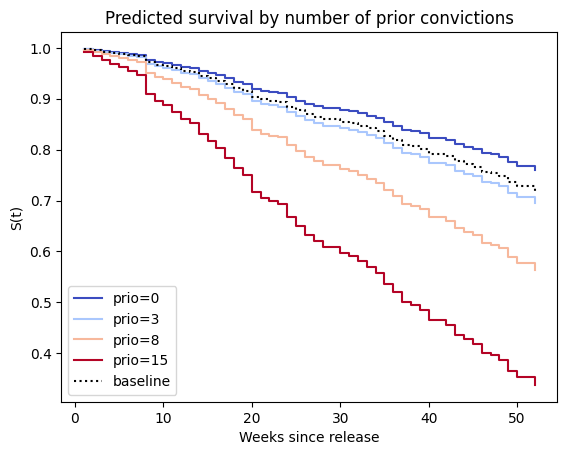

In [21]:
cph.plot_partial_effects_on_outcome(covariates="prio", values=[0, 3, 8, 15], cmap="coolwarm")
plt.title("Predicted survival by number of prior convictions")
plt.xlabel("Weeks since release")
plt.ylabel("S(t)")
plt.show()

## 6. Check the proportional hazards assumption

The Cox model assumes each hazard ratio is **constant over time**.
We test this with **Schoenfeld residuals**: if a variable's effect drifts over time, its residuals show a trend.

- `proportional_hazard_test` gives one p-value per covariate. **Small p (< 0.05) = evidence the PH assumption is violated** for that variable.
- `cph.check_assumptions(...)` runs the same test, prints advice, and draws residual plots.

In [24]:
ph = proportional_hazard_test(cph, df, time_transform="rank")
ph.print_summary()

<lifelines.StatisticalResult: proportional_hazard_test>
    time_transform = rank
 null_distribution = chi squared
degrees_of_freedom = 1
             model = <lifelines.CoxPHFitter: fitted with 432 total observations, 318 right-censored observations>
         test_name = proportional_hazard_test

---
      test_statistic      p  -log2(p)
age            11.45 <0.005     10.45
fin             0.02   0.90      0.15
mar             0.71   0.40      1.32
paro            0.13   0.71      0.49
prio            0.02   0.89      0.17
race            1.43   0.23      2.11
wexp            7.31   0.01      7.19


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.



<lifelines.StatisticalResult: proportional_hazard_test>
 null_distribution = chi squared
degrees_of_freedom = 1
             model = <lifelines.CoxPHFitter: fitted with 432 total observations, 318 right-censored observations>
         test_name = proportional_hazard_test

---
           test_statistic      p  -log2(p)
age  km             11.03 <0.005     10.12
     rank           11.45 <0.005     10.45
fin  km              0.02   0.89      0.17
     rank            0.02   0.90      0.15
mar  km              0.60   0.44      1.19
     rank            0.71   0.40      1.32
paro km              0.12   0.73      0.45
     rank            0.13   0.71      0.49
prio km              0.02   0.88      0.18
     rank            0.02   0.89      0.17
race km              1.44   0.23      2.12
     rank            1.43   0.23      2.11
wexp km              7.48   0.01      7.32
     rank            7.31   0.01      7.19



1. Variable 'age' failed the non-proportional test: p-value is 0.0007.

   Advice 1: the functional form of the variable 'age' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'age' using pd.cut, and then specify it in `strata=['age',
...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


2. Variable 'wexp' failed the non-proportional test: p-value is 0.0063.

   Advice: with so few unique values (only 2), you can include `strata=['wexp', ...]` in the call in
`.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a mome

[[<Axes: xlabel='rank-transformed time\n(p=0.9023)'>,
  <Axes: xlabel='km-transformed time\n(p=0.8900)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0007)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0009)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.2323)'>,
  <Axes: xlabel='km-transformed time\n(p=0.2306)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0068)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0063)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.3996)'>,
  <Axes: xlabel='km-transformed time\n(p=0.4382)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.7140)'>,
  <Axes: xlabel='km-transformed time\n(p=0.7337)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.8908)'>,
  <Axes: xlabel='km-transformed time\n(p=0.8806)'>]]

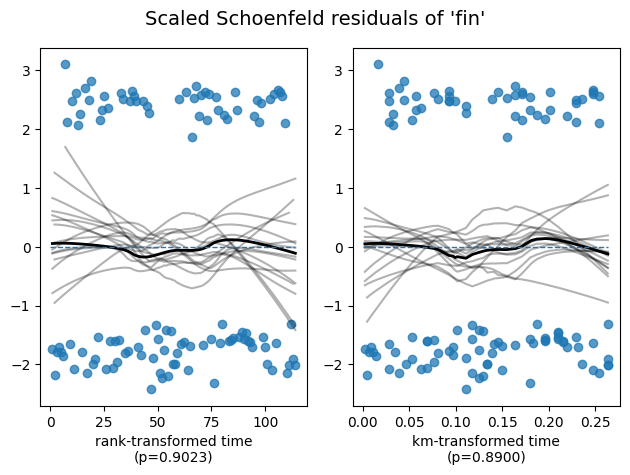

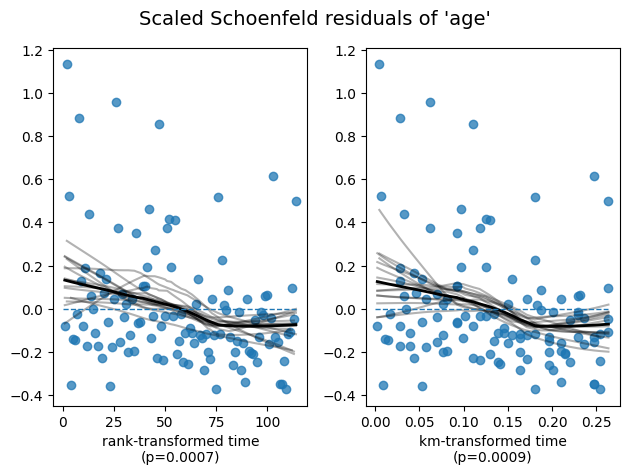

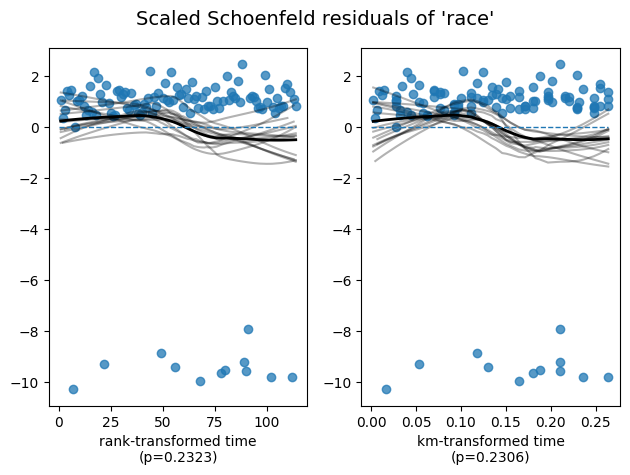

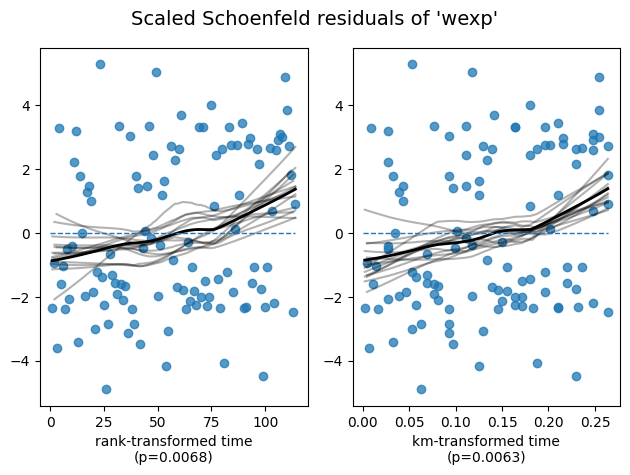

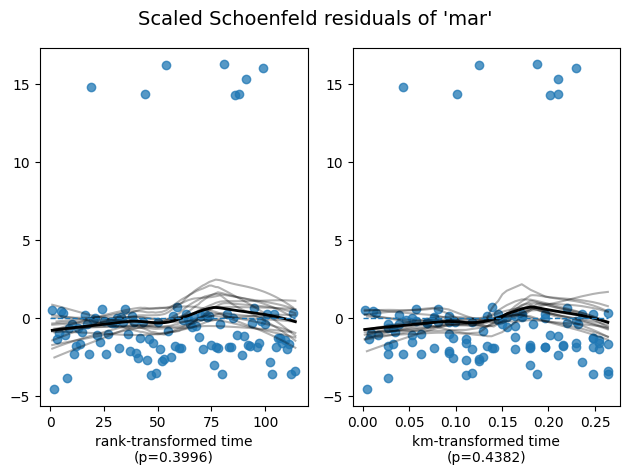

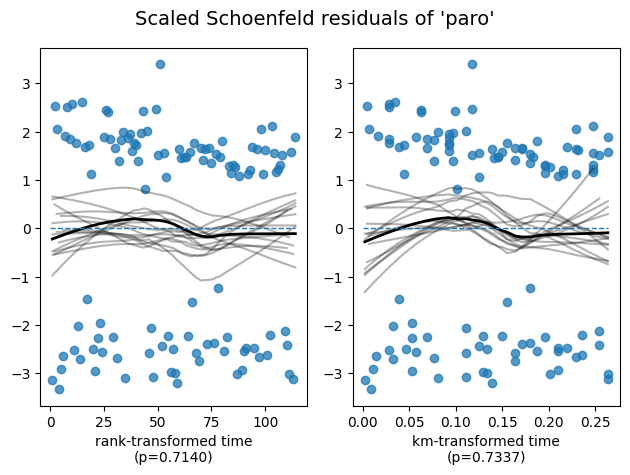

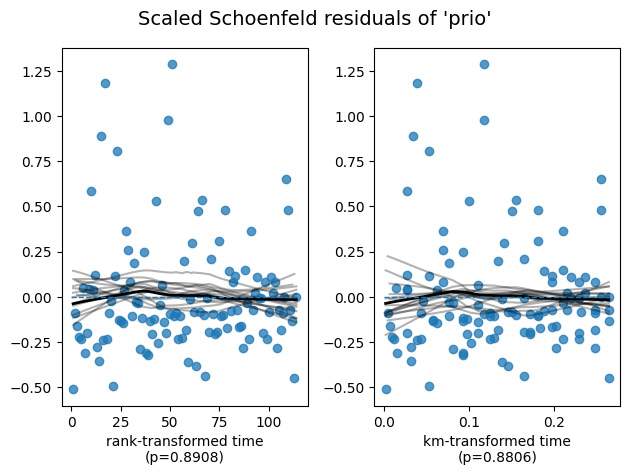

In [26]:
cph.check_assumptions(df, p_value_threshold=0.05, show_plots=True)